<a href="https://colab.research.google.com/github/OwenLoughery/Project3-Wine_Reviews/blob/main/4401_Project_3_Model_Stanley.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Classification between two similar wines

##Setup: Finding similar wines in pairs

In [ ]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
df = pd.read_csv("winemag-data-130k-v2.csv")

wine_data = df.dropna(
    subset=["variety", "description"]
).copy()

variety_counts = wine_data["variety"].value_counts()

valid_varieties = variety_counts[
    variety_counts >= 200
].index

wine_data = wine_data[
    wine_data["variety"].isin(valid_varieties)
].copy()

print("Varieties:", wine_data["variety"].nunique())
print("Reviews:", len(wine_data))

Varieties: 62
Reviews: 118263


In [ ]:
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    max_features=10000,
    sublinear_tf=True
)

X_tfidf = tfidf.fit_transform(
    wine_data["description"]
)

print("TF-IDF matrix shape:", X_tfidf.shape)

TF-IDF matrix shape: (118263, 10000)


In [ ]:
varieties = sorted(wine_data["variety"].unique())

variety_vectors = []

for variety in varieties:

    mask = (
        wine_data["variety"] == variety
    ).to_numpy()

    mean_vector = np.asarray(
        X_tfidf[mask].mean(axis=0)
    ).ravel()

    variety_vectors.append(mean_vector)

variety_vectors = np.vstack(variety_vectors)

In [ ]:
similarity_matrix = cosine_similarity(variety_vectors)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=varieties,
    columns=varieties
)

# Extract unique pairs without self-comparisons
upper_i, upper_j = np.triu_indices(
    len(varieties), k=1
)

similar_pairs = pd.DataFrame({
    "Wine 1": np.array(varieties)[upper_i],
    "Wine 2": np.array(varieties)[upper_j],
    "Similarity": similarity_matrix[upper_i, upper_j]
})

similar_pairs = (
    similar_pairs
    .sort_values("Similarity", ascending=False)
    .reset_index(drop=True)
)

display(similar_pairs.head(15))

,Wine 1,Wine 2,Similarity
0,Tempranillo,Tempranillo Blend,0.950381
1,Nebbiolo,Sangiovese,0.891038
2,Malbec,Tempranillo,0.878627
3,Cabernet Sauvignon,Merlot,0.864705
4,Gamay,Portuguese Red,0.837147
5,Malbec,Tempranillo Blend,0.832999
6,Garnacha,Tempranillo,0.829374
7,Cabernet Franc,Cabernet Sauvignon,0.827344
8,Bordeaux-style White Blend,Portuguese White,0.825607
9,Bordeaux-style Red Blend,Portuguese Red,0.821633


In [ ]:
similar_pairs["Wine 1 Count"] = (
    similar_pairs["Wine 1"].map(variety_counts)
)

similar_pairs["Wine 2 Count"] = (
    similar_pairs["Wine 2"].map(variety_counts)
)

display(similar_pairs.head(15))

,Wine 1,Wine 2,Similarity,Wine 1 Count,Wine 2 Count
0,Tempranillo,Tempranillo Blend,0.950381,1810,588
1,Nebbiolo,Sangiovese,0.891038,2804,2707
2,Malbec,Tempranillo,0.878627,2652,1810
3,Cabernet Sauvignon,Merlot,0.864705,9472,3102
4,Gamay,Portuguese Red,0.837147,1025,2466
5,Malbec,Tempranillo Blend,0.832999,2652,588
6,Garnacha,Tempranillo,0.829374,326,1810
7,Cabernet Franc,Cabernet Sauvignon,0.827344,1353,9472
8,Bordeaux-style White Blend,Portuguese White,0.825607,1066,1159
9,Bordeaux-style Red Blend,Portuguese Red,0.821633,6915,2466


##Model Building

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

In [ ]:
pair_df = df[
    df["variety"].isin(["Nebbiolo", "Sangiovese"])
].copy()

pair_df = pair_df.dropna(
    subset=["variety", "description"]
)

pair_df = pair_df[
    pair_df["description"].str.strip() != ""
].copy()

# Remove exact duplicate descriptions to reduce leakage
# Conflicting labels for identical text should be investigated
conflicts = (
    pair_df.groupby("description")["variety"].nunique()
)

ambiguous = conflicts[conflicts > 1].index

print("Conflicting descriptions:", len(ambiguous))

pair_df = pair_df[
    ~pair_df["description"].isin(ambiguous)
].drop_duplicates(subset=["description"]).copy()

X = pair_df["description"]
y = pair_df["variety"]

# 80% development, 20% final test
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 80% of development for training, 20% for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Conflicting descriptions: 0
Training: 3239
Validation: 810
Test: 1013


In [ ]:
model_configs = {
    "Simple": {
        "max_features": 100,
        "ngram_range": (1, 1),
        "C": 1.0
    },
    "Moderate": {
        "max_features": 1000,
        "ngram_range": (1, 1),
        "C": 1.0
    },
    "Complex": {
        "max_features": 5000,
        "ngram_range": (1, 2),
        "C": 10.0
    }
}

def create_model(config):
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=config["max_features"],
            ngram_range=config["ngram_range"],
            min_df=1,
            stop_words="english"
        )),
        ("clf", LogisticRegression(
            C=config["C"],
            max_iter=2000,
            random_state=42
        ))
    ])

In [ ]:
sizes = [80, 320, 1200, 3000]

sizes = [s for s in sizes if s <= len(X_train)]

# Create a balanced, nested ordering of training observations
rng = np.random.default_rng(42)

classes = sorted(y_train.unique())

class_indices = [
    rng.permutation(np.flatnonzero(y_train.to_numpy() == cls))
    for cls in classes
]

# Interleave the two classes
ordered_indices = []

for i in range(max(map(len, class_indices))):
    for indices in class_indices:
        if i < len(indices):
            ordered_indices.append(indices[i])

results = []

for size in sizes:
    idx = ordered_indices[:size]

    X_subset = X_train.iloc[idx]
    y_subset = y_train.iloc[idx]

    for name, config in model_configs.items():

        model = create_model(config)

        model.fit(X_subset, y_subset)

        train_acc = accuracy_score(
            y_subset, model.predict(X_subset)
        )

        val_acc = accuracy_score(
            y_val, model.predict(X_val)
        )

        results.append({
            "Model": name,
            "Training Size": size,
            "Train Accuracy": train_acc,
            "Validation Accuracy": val_acc,
            "Gap": train_acc - val_acc
        })

results_df = pd.DataFrame(results)

display(results_df)

,Model,Training Size,Train Accuracy,Validation Accuracy,Gap
0,Simple,80,0.912500,0.701235,0.211265
1,Moderate,80,0.987500,0.722222,0.265278
2,Complex,80,1.000000,0.706173,0.293827
3,Simple,320,0.875000,0.761728,0.113272
4,Moderate,320,0.968750,0.775309,0.193441
5,Complex,320,1.000000,0.772840,0.227160
6,Simple,1200,0.820000,0.774074,0.045926
7,Moderate,1200,0.908333,0.818519,0.089815
8,Complex,1200,1.000000,0.819753,0.180247
9,Simple,3000,0.804667,0.787654,0.017012


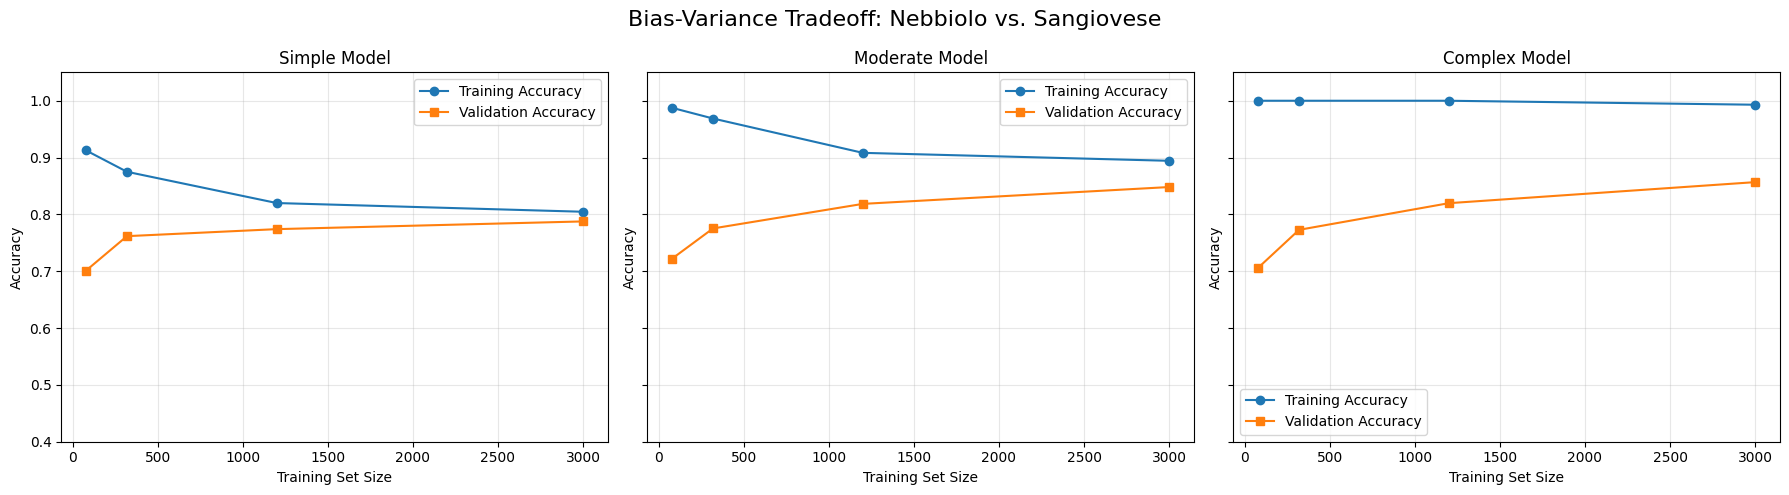

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, name in zip(axes, model_configs):

    subset = results_df[
        results_df["Model"] == name
    ]

    ax.plot(
        subset["Training Size"],
        subset["Train Accuracy"],
        marker="o",
        label="Training Accuracy"
    )

    ax.plot(
        subset["Training Size"],
        subset["Validation Accuracy"],
        marker="s",
        label="Validation Accuracy"
    )

    ax.set_title(f"{name} Model")
    ax.set_xlabel("Training Set Size")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0.4, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "Bias-Variance Tradeoff: Nebbiolo vs. Sangiovese",
    fontsize=16
)

plt.tight_layout()
plt.show()

##Diving into individual models for Bias-Variance tradeoff

Simple model of 40 observations each

In [ ]:
rng = np.random.default_rng(42)

nebbiolo_idx = rng.choice(
    np.flatnonzero(y_train.to_numpy() == "Nebbiolo"),
    size=40,
    replace=False
)

sangiovese_idx = rng.choice(
    np.flatnonzero(y_train.to_numpy() == "Sangiovese"),
    size=40,
    replace=False
)

subset_idx = np.concatenate([nebbiolo_idx, sangiovese_idx])

X_small = X_train.iloc[subset_idx]
y_small = y_train.iloc[subset_idx]

print(y_small.value_counts())

variety
Nebbiolo      40
Sangiovese    40
Name: count, dtype: int64


In [ ]:
model_1 = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 1),
        max_features=100,
        min_df=1,
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        C=0.1,
        max_iter=2000,
        random_state=12
    ))
])

In [ ]:
model_1.fit(X_small, y_small)

train_pred = model_1.predict(X_small)
val_pred = model_1.predict(X_val)

train_acc = accuracy_score(y_small, train_pred)
val_acc = accuracy_score(y_val, val_pred)

print("Experiment 1: Simple Unigram Model")
print(f"Training Accuracy:   {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Generalization Gap:  {train_acc - val_acc:.4f}")

Experiment 1: Simple Unigram Model
Training Accuracy:   0.9500
Validation Accuracy: 0.6160
Generalization Gap:  0.3340


In [ ]:
experiment_log = []

experiment_log.append({
    "Experiment": 1,
    "Training Size": len(X_small),
    "N-grams": "Unigram",
    "Max Features": 100,
    "C": 0.1,
    "Train Accuracy": train_acc,
    "Validation Accuracy": val_acc,
    "Gap": train_acc - val_acc
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.1,0.95,0.616049,0.333951


Training accuracy is high but validation accuracy is much lower. Increase sample size

In [ ]:
# Get indices of observations not used in Experiment 1
remaining_idx = np.setdiff1d(
    np.arange(len(X_train)),
    subset_idx
)

remaining_nebbiolo = remaining_idx[
    y_train.iloc[remaining_idx].to_numpy() == "Nebbiolo"
]

remaining_sangiovese = remaining_idx[
    y_train.iloc[remaining_idx].to_numpy() == "Sangiovese"
]

# Add 20 new reviews from each variety
new_nebbiolo = rng.choice(
    remaining_nebbiolo, size=120, replace=False
)

new_sangiovese = rng.choice(
    remaining_sangiovese, size=120, replace=False
)

subset_idx_160 = np.concatenate([
    subset_idx,
    new_nebbiolo,
    new_sangiovese
])

X_small_160 = X_train.iloc[subset_idx_160]
y_small_160 = y_train.iloc[subset_idx_160]

# Same model configuration as Experiment 1
model_2 = create_model({
    "max_features": 100,
    "ngram_range": (1, 1),
    "C": 0.1
})

model_2.fit(X_small_160, y_small_160)

# Evaluate
train_acc_2 = accuracy_score(
    y_small_160, model_2.predict(X_small_160)
)

val_acc_2 = accuracy_score(
    y_val, model_2.predict(X_val)
)

print(f"Training Accuracy:   {train_acc_2:.4f}")
print(f"Validation Accuracy: {val_acc_2:.4f}")
print(f"Generalization Gap:  {train_acc_2 - val_acc_2:.4f}")

Training Accuracy:   0.8156
Validation Accuracy: 0.7012
Generalization Gap:  0.1144


In [ ]:
experiment_log.append({
    "Experiment": 2,
    "Training Size": len(X_small_160),
    "N-grams": "Unigram",
    "Max Features": 100,
    "C": 0.1,
    "Train Accuracy": train_acc_2,
    "Validation Accuracy": val_acc_2,
    "Gap": train_acc_2 - val_acc_2
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.1,0.950000,0.616049,0.333951
1,2,320,Unigram,100,0.1,0.815625,0.701235,0.114390


Training accuracy and validation accuracy is getting closer. Let's still increase sample size

In [ ]:
# Existing 320 training observations
current_idx = subset_idx_160

# Identify remaining observations
remaining_idx = np.setdiff1d(
    np.arange(len(X_train)),
    current_idx
)

# Separate remaining observations by variety
remaining_nebbiolo = remaining_idx[
    y_train.iloc[remaining_idx].to_numpy() == "Nebbiolo"
]

remaining_sangiovese = remaining_idx[
    y_train.iloc[remaining_idx].to_numpy() == "Sangiovese"
]

rng = np.random.default_rng(41)

new_nebbiolo = rng.choice(
    remaining_nebbiolo,
    size=440,
    replace=False
)

new_sangiovese = rng.choice(
    remaining_sangiovese,
    size=440,
    replace=False
)

subset_idx_1200 = np.concatenate([
    current_idx,
    new_nebbiolo,
    new_sangiovese
])

X_small_1200 = X_train.iloc[subset_idx_1200]
y_small_1200 = y_train.iloc[subset_idx_1200]

# Keep exactly the same model configuration
model_3 = create_model({
    "max_features": 100,
    "ngram_range": (1, 1),
    "C": 0.1
})

model_3.fit(X_small_1200, y_small_1200)

train_acc_3 = accuracy_score(
    y_small_1200,
    model_3.predict(X_small_1200)
)

val_acc_3 = accuracy_score(
    y_val,
    model_3.predict(X_val)
)

print(f"Training Accuracy:   {train_acc_3:.4f}")
print(f"Validation Accuracy: {val_acc_3:.4f}")
print(f"Generalization Gap:  {train_acc_3 - val_acc_3:.4f}")

Training Accuracy:   0.7925
Validation Accuracy: 0.7593
Generalization Gap:  0.0332


In [ ]:
experiment_log.append({
    "Experiment": 3,
    "Training Size": len(X_small_1200),
    "N-grams": "Unigram",
    "Max Features": 100,
    "C": 0.1,
    "Train Accuracy": train_acc_3,
    "Validation Accuracy": val_acc_3,
    "Gap": train_acc_3 - val_acc_3
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.1,0.950000,0.616049,0.333951
1,2,320,Unigram,100,0.1,0.815625,0.701235,0.114390
2,3,1200,Unigram,100,0.1,0.792500,0.759259,0.033241


Gap is much smaller now, let's increase complexity but adding more features

In [ ]:
model_4 = create_model({
    "max_features": 1000,
    "ngram_range": (1, 1),
    "C": 0.1
})

model_4.fit(X_small_1200, y_small_1200)

train_acc_4 = accuracy_score(
    y_small_1200,
    model_4.predict(X_small_1200)
)

val_acc_4 = accuracy_score(
    y_val,
    model_4.predict(X_val)
)

print(f"Training Accuracy:   {train_acc_4:.4f}")
print(f"Validation Accuracy: {val_acc_4:.4f}")
print(f"Generalization Gap:  {train_acc_4 - val_acc_4:.4f}")

Training Accuracy:   0.8417
Validation Accuracy: 0.7988
Generalization Gap:  0.0429


In [ ]:
experiment_log.append({
    "Experiment": 4,
    "Training Size": len(X_small_1200),
    "N-grams": "Unigram",
    "Max Features": 1000,
    "C": 0.1,
    "Train Accuracy": train_acc_4,
    "Validation Accuracy": val_acc_4,
    "Gap": train_acc_4 - val_acc_4
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.1,0.950000,0.616049,0.333951
1,2,320,Unigram,100,0.1,0.815625,0.701235,0.114390
2,3,1200,Unigram,100,0.1,0.792500,0.759259,0.033241
3,4,1200,Unigram,1000,0.1,0.841667,0.798765,0.042901


Accuracy improved overall and gap barely changed, let's add in bigrams

In [ ]:
model_5 = create_model({
    "max_features": 1000,
    "ngram_range": (1, 2),
    "C": 0.1
})

# Same 1,200 training observations
model_5.fit(X_small_1200, y_small_1200)

train_acc_5 = accuracy_score(
    y_small_1200,
    model_5.predict(X_small_1200)
)

val_acc_5 = accuracy_score(
    y_val,
    model_5.predict(X_val)
)

print(f"Training Accuracy:   {train_acc_5:.4f}")
print(f"Validation Accuracy: {val_acc_5:.4f}")
print(f"Generalization Gap:  {train_acc_5 - val_acc_5:.4f}")

Training Accuracy:   0.8492
Validation Accuracy: 0.7963
Generalization Gap:  0.0529


In [ ]:
experiment_log.append({
    "Experiment": 5,
    "Training Size": len(X_small_1200),
    "N-grams": "Bigram",
    "Max Features": 1000,
    "C": 0.1,
    "Train Accuracy": train_acc_5,
    "Validation Accuracy": val_acc_5,
    "Gap": train_acc_5 - val_acc_5
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.1,0.950000,0.616049,0.333951
1,2,320,Unigram,100,0.1,0.815625,0.701235,0.114390
2,3,1200,Unigram,100,0.1,0.792500,0.759259,0.033241
3,4,1200,Unigram,1000,0.1,0.841667,0.798765,0.042901
4,5,1200,Bigram,1000,0.1,0.849167,0.796296,0.052870


Minimal improvement, so were going to increase sample size again

In [ ]:
current_idx = subset_idx_1200

# Find unused training observations
remaining_idx = np.setdiff1d(
    np.arange(len(X_train)),
    current_idx
)

remaining_nebbiolo = remaining_idx[
    y_train.iloc[remaining_idx].to_numpy() == "Nebbiolo"
]

remaining_sangiovese = remaining_idx[
    y_train.iloc[remaining_idx].to_numpy() == "Sangiovese"
]

# Add 400 observations from each variety
rng = np.random.default_rng(12)

new_nebbiolo = rng.choice(
    remaining_nebbiolo,
    size=800,
    replace=False
)

new_sangiovese = rng.choice(
    remaining_sangiovese,
    size=800,
    replace=False
)

subset_idx_2800 = np.concatenate([
    current_idx,
    new_nebbiolo,
    new_sangiovese
])

X_small_2800 = X_train.iloc[subset_idx_2800]
y_small_2800 = y_train.iloc[subset_idx_2800]

# Keep exactly the same model configuration
model_6 = create_model({
    "max_features": 1000,
    "ngram_range": (1, 2),
    "C": 0.1
})

model_6.fit(X_small_2800, y_small_2800)

train_acc_6 = accuracy_score(
    y_small_2800,
    model_6.predict(X_small_2800)
)

val_acc_6 = accuracy_score(
    y_val,
    model_6.predict(X_val)
)

print(f"Training Accuracy:   {train_acc_6:.4f}")
print(f"Validation Accuracy: {val_acc_6:.4f}")
print(f"Generalization Gap:  {train_acc_6 - val_acc_6:.4f}")

Training Accuracy:   0.8446
Validation Accuracy: 0.8160
Generalization Gap:  0.0286


In [ ]:
experiment_log.append({
    "Experiment": 6,
    "Training Size": len(X_small_2800),
    "N-grams": "Bigram",
    "Max Features": 1000,
    "C": 0.1,
    "Train Accuracy": train_acc_6,
    "Validation Accuracy": val_acc_6,
    "Gap": train_acc_6 - val_acc_6
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.1,0.950000,0.616049,0.333951
1,2,320,Unigram,100,0.1,0.815625,0.701235,0.114390
2,3,1200,Unigram,100,0.1,0.792500,0.759259,0.033241
3,4,1200,Unigram,1000,0.1,0.841667,0.798765,0.042901
4,5,1200,Bigram,1000,0.1,0.849167,0.796296,0.052870
5,6,2800,Bigram,1000,0.1,0.844643,0.816049,0.028593


Best validation accuracy yet. Let's increase complexity by adding more features

In [ ]:
model_7 = create_model({
    "max_features": 5000,
    "ngram_range": (1, 2),
    "C": 0.1
})

model_7.fit(X_small_2800, y_small_2800)

train_acc_7 = accuracy_score(
    y_small_2800,
    model_7.predict(X_small_2800)
)

val_acc_7 = accuracy_score(
    y_val,
    model_7.predict(X_val)
)

print(f"Training Accuracy:   {train_acc_7:.4f}")
print(f"Validation Accuracy: {val_acc_7:.4f}")
print(f"Generalization Gap:  {train_acc_7 - val_acc_7:.4f}")

Training Accuracy:   0.8632
Validation Accuracy: 0.8123
Generalization Gap:  0.0509


In [ ]:
experiment_log.append({
    "Experiment": 7,
    "Training Size": len(X_small_2800),
    "N-grams": "Bigram",
    "Max Features": 5000,
    "C": 0.1,
    "Train Accuracy": train_acc_7,
    "Validation Accuracy": val_acc_7,
    "Gap": train_acc_7 - val_acc_7
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.1,0.950000,0.616049,0.333951
1,2,320,Unigram,100,0.1,0.815625,0.701235,0.114390
2,3,1200,Unigram,100,0.1,0.792500,0.759259,0.033241
3,4,1200,Unigram,1000,0.1,0.841667,0.798765,0.042901
4,5,1200,Bigram,1000,0.1,0.849167,0.796296,0.052870
5,6,2800,Bigram,1000,0.1,0.844643,0.816049,0.028593
6,7,2800,Bigram,5000,0.1,0.863214,0.812346,0.050869


No improvement, so we are using stronger regularization

In [ ]:
print("Available training observations per variety:")
print(y_train.value_counts())

print("\nTotal training observations:", len(y_train))

print("\nRemaining unused observations:")
print(y_train.value_counts() - y_small_2800.value_counts())

Available training observations per variety:
variety
Nebbiolo      1665
Sangiovese    1574
Name: count, dtype: int64

Total training observations: 3239

Remaining unused observations:
variety
Nebbiolo      265
Sangiovese    174
Name: count, dtype: int64


In [ ]:
model_8 = create_model({
    "max_features": 5000,
    "ngram_range": (1, 2),
    "C": 0.01
})

# Use the same 2,800 training observations
model_8.fit(X_small_2800, y_small_2800)

train_acc_8 = accuracy_score(
    y_small_2800,
    model_8.predict(X_small_2800)
)

val_acc_8 = accuracy_score(
    y_val,
    model_8.predict(X_val)
)

print(f"Training Accuracy:   {train_acc_8:.4f}")
print(f"Validation Accuracy: {val_acc_8:.4f}")
print(f"Generalization Gap:  {train_acc_8 - val_acc_8:.4f}")

Training Accuracy:   0.8389
Validation Accuracy: 0.8037
Generalization Gap:  0.0352


In [ ]:
experiment_log.append({
    "Experiment": 8,
    "Training Size": len(X_small_2800),
    "N-grams": "Bigram",
    "Max Features": 5000,
    "C": 0.01,
    "Train Accuracy": train_acc_8,
    "Validation Accuracy": val_acc_8,
    "Gap": train_acc_8 - val_acc_8
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.10,0.950000,0.616049,0.333951
1,2,320,Unigram,100,0.10,0.815625,0.701235,0.114390
2,3,1200,Unigram,100,0.10,0.792500,0.759259,0.033241
3,4,1200,Unigram,1000,0.10,0.841667,0.798765,0.042901
4,5,1200,Bigram,1000,0.10,0.849167,0.796296,0.052870
5,6,2800,Bigram,1000,0.10,0.844643,0.816049,0.028593
6,7,2800,Bigram,5000,0.10,0.863214,0.812346,0.050869
7,8,2800,Bigram,5000,0.01,0.838929,0.803704,0.035225


No improvement again, we'll go back to experiment 6 and add the remaining observations

In [ ]:
model_9 = create_model({
    "max_features": 1000,
    "ngram_range": (1, 2),
    "C": 0.1
})

model_9.fit(X_train, y_train)

train_acc_9 = accuracy_score(
    y_train,
    model_9.predict(X_train)
)

val_acc_9 = accuracy_score(
    y_val,
    model_9.predict(X_val)
)

print(f"Training Accuracy:   {train_acc_9:.4f}")
print(f"Validation Accuracy: {val_acc_9:.4f}")
print(f"Generalization Gap:  {train_acc_9 - val_acc_9:.4f}")

Training Accuracy:   0.8456
Validation Accuracy: 0.8185
Generalization Gap:  0.0271


In [ ]:
experiment_log.append({
    "Experiment": 9,
    "Training Size": len(X_train),
    "N-grams": "Bigram",
    "Max Features": 5000,
    "C": 0.01,
    "Train Accuracy": train_acc_9,
    "Validation Accuracy": val_acc_9,
    "Gap": train_acc_9 - val_acc_9
})

display(pd.DataFrame(experiment_log))

,Experiment,Training Size,N-grams,Max Features,C,Train Accuracy,Validation Accuracy,Gap
0,1,80,Unigram,100,0.10,0.950000,0.616049,0.333951
1,2,320,Unigram,100,0.10,0.815625,0.701235,0.114390
2,3,1200,Unigram,100,0.10,0.792500,0.759259,0.033241
3,4,1200,Unigram,1000,0.10,0.841667,0.798765,0.042901
4,5,1200,Bigram,1000,0.10,0.849167,0.796296,0.052870
5,6,2800,Bigram,1000,0.10,0.844643,0.816049,0.028593
6,7,2800,Bigram,5000,0.10,0.863214,0.812346,0.050869
7,8,2800,Bigram,5000,0.01,0.838929,0.803704,0.035225
8,9,3239,Bigram,5000,0.01,0.845631,0.818519,0.027113


##Final Model

Final Test Accuracy: 0.8282

Classification Report:
              precision    recall  f1-score   support

    Nebbiolo       0.81      0.87      0.84       521
  Sangiovese       0.85      0.79      0.82       492

    accuracy                           0.83      1013
   macro avg       0.83      0.83      0.83      1013
weighted avg       0.83      0.83      0.83      1013



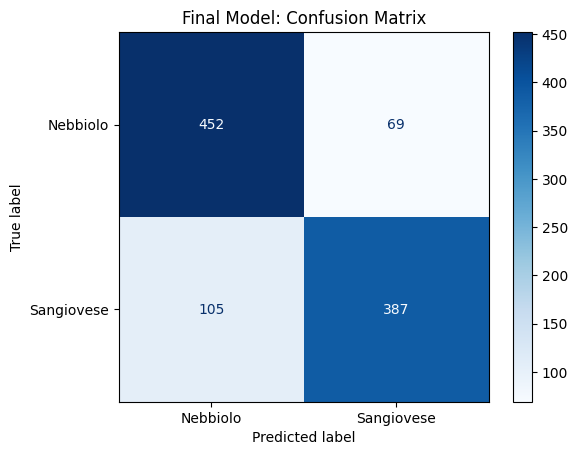

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Combine training and validation datasets
X_final_train = pd.concat([X_train, X_val])
y_final_train = pd.concat([y_train, y_val])

# Final selected model
final_model = create_model({
    "max_features": 1000,
    "ngram_range": (1, 2),
    "C": 0.1
})

final_model.fit(X_final_train, y_final_train)

# Evaluate on untouched test set
y_test_pred = final_model.predict(X_test)

print("Final Test Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=["Nebbiolo", "Sangiovese"],
    cmap="Blues"
)

plt.title("Final Model: Confusion Matrix")
plt.show()


In [ ]:
# Extract vectorizer and classifier
tfidf = final_model.named_steps["tfidf"]
classifier = final_model.named_steps["clf"]

# Get feature names and coefficients
feature_names = tfidf.get_feature_names_out()
coefficients = classifier.coef_[0]

print("Class order:", classifier.classes_)

# Positive coefficients favor classes_[1]
# Negative coefficients favor classes_[0]

top_n = 15

negative_idx = np.argsort(coefficients)[:top_n]
positive_idx = np.argsort(coefficients)[-top_n:][::-1]

important_words = pd.DataFrame({
    classifier.classes_[0]: feature_names[negative_idx],
    f"{classifier.classes_[0]} Coefficient": coefficients[negative_idx],
    classifier.classes_[1]: feature_names[positive_idx],
    f"{classifier.classes_[1]} Coefficient": coefficients[positive_idx]
})

display(important_words)


Class order: ['Nebbiolo' 'Sangiovese']


,Nebbiolo,Nebbiolo Coefficient,Sangiovese,Sangiovese Coefficient
0,barolo,-1.893632,sangiovese,2.403681
1,nebbiolo,-1.684693,chianti,1.000195
2,rose,-1.292110,flavors,0.966559
3,barbaresco,-1.030024,plum,0.929365
4,licorice,-0.751040,easy,0.760864
5,firm,-0.719896,light,0.720902
6,cola,-0.638384,skinned,0.630308
7,balsamic,-0.635187,chianti classico,0.601579
8,years,-0.603103,classico,0.593134
9,cru,-0.586632,black,0.583191
